In [7]:
# Step 1: load the pipeline code (sam2_pipeline/fruit_sam2.py) and point it at a scratch project folder.
import sys, shutil
from pathlib import Path
import numpy as np, pandas as pd
from PIL import Image
from tqdm.auto import tqdm

REPO = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "sam2_pipeline" / "fruit_sam2.py").exists())
sys.path.insert(0, str(REPO / "sam2_pipeline"))
import fruit_sam2 as F          # first run: fetches Meta's SAM 2 code and installs the packages it needs

F.SAM2_SIZE = "tiny"            # tiny | small | base_plus | large (base_plus is the pipeline's default; needs a GPU to be quick)
if F.DEVICE == "cpu":
    F.SAM2_IMAGE_SIZE = 512     # faster on a CPU, a little less accurate; GPUs use SAM 2's full 1024
F.use_project(REPO / "data" / "count_test")

IMAGES = REPO / "yolo11_pipeline" / "data" / "wgisd_seg" / "images" / "test"     # the 27 WGISD test photos
print("running on", F.GPU_NAME or "CPU", "· repository:", REPO, "· results:", F.ROOT)

running on CPU · repository: C:\Users\mtv35\Capstone-MSU_Fruit · results: C:\Users\mtv35\Capstone-MSU_Fruit\data\count_test


In [8]:
# Step 2: the detector that finds clusters, and the detector → SAM 2.1 pipeline built on it.
DETECTOR = F.UltralyticsModel(REPO / "yolo11_pipeline" / "runs" / "yolo11_wgisd2" / "weights" / "best.pt", conf=0.25, imgsz=512)
# DETECTOR = F.UltralyticsModel("yoloe-26m-seg.pt", text="grape cluster", conf=0.2)   # zero-shot, downloads the weights

FINETUNED = None                # a fine-tuned SAM 2.1 checkpoint (.pt) to test instead of Meta's pretrained weights, once the team has one

PIPELINE = F.DetectThenSAM2(DETECTOR, ckpt=FINETUNED)
PIPELINE.prepare()              # loads the detector and SAM 2.1 now, so model loading is not timed as inference

loading best.pt (downloaded on first use) …


In [9]:
# Step 3: the hand counts (grape clusters per photo).
GROUND_TRUTH = [
    ("SYH_2017-04-27_1322.jpg", 20),
    ("SYH_2017-04-27_1318.jpg", 8),
    ("SYH_2017-04-27_1304.jpg", 7),
    ("SYH_2017-04-27_1269.jpg", 11),
    ("SYH_2017-04-27_1239.jpg", 21),
    ("SVB_20180427_151818928.jpg", 21),
    ("SVB_1972.jpg", 22),
    ("SVB_1954.jpg", 19),
    ("SVB_1944.jpg", 18),
    ("SVB_1935.jpg", 25),
    ("CSV_20180427_144723166_HDR.jpg", 14),
    ("CSV_20180427_144535647.jpg", 13),
    ("CSV_20180427_144507419.jpg", 16),
    ("CSV_1898.jpg", 11),
    ("CSV_1877.jpg", 8),
    ("CFR_1666.jpg", 12),
    ("CFR_1651.jpg", 14),
    ("CFR_1643.jpg", 15),
    ("CFR_1641.jpg", 30),
    ("CFR_1639.jpg", 17),
    ("CFR_1638.jpg", 10),
    ("CDY_2054.jpg", 16),
    ("CDY_2051.jpg", 11),
    ("CDY_2046.jpg", 10),
    ("CDY_2043.jpg", 10),
    ("CDY_2040.jpg", 8),
    ("CDY_2015.jpg", 20),
]
print(len(GROUND_TRUTH), "photos,", sum(n for _, n in GROUND_TRUTH), "clusters counted by hand")

27 photos, 407 clusters counted by hand


In [10]:
# Step 4: run the detector and the detector → SAM 2.1 pipeline on every photo and count the clusters.
STILLS = F.ROOT / "stills"                       # one single-frame clip per photo
OVERLAYS = F.RESULTS / "overlays"
OVERLAYS.mkdir(parents=True, exist_ok=True)

def still_clip(photo):
    """Turn one photo into a one-frame clip the pipeline can read."""
    d = STILLS / photo.stem
    d.mkdir(parents=True, exist_ok=True)
    frame = d / "00000.jpg"
    if not frame.exists():
        shutil.copy2(photo, frame)
    return F.Clip(photo.stem, root=STILLS)

rows = []
for filename, truth in tqdm(GROUND_TRUTH):
    photo = IMAGES / filename
    if not photo.exists():
        rows.append(dict(image=filename, truth=truth, status="missing image"))
        continue
    try:
        clip = still_clip(photo)
        boxes, scores, _ = DETECTOR.detect(clip.image(0))        # the detector alone: one box per cluster it finds
        ids = PIPELINE.predict(clip)                             # detector boxes → SAM 2.1 masks: [1, H, W] object ids, 0 = background
        objects = np.unique(ids[0])
        n_sam2 = int((objects != 0).sum())
        Image.fromarray(F.overlay(clip.image(0), ids[0])).save(OVERLAYS / filename)
        rows.append(dict(image=filename, truth=truth, yolo=len(boxes), sam2=n_sam2, status="OK"))
    except Exception as e:
        rows.append(dict(image=filename, truth=truth, status=f"{type(e).__name__}: {e}"))

df = pd.DataFrame(rows, columns=["image", "truth", "yolo", "sam2", "status"])
df["yolo_error"] = df["yolo"] - df["truth"]
df["sam2_error"] = df["sam2"] - df["truth"]
df.to_csv(F.RESULTS / "count_test.csv", index=False)
display(df)

  0%|          | 0/27 [00:00<?, ?it/s]

,image,truth,yolo,sam2,status,yolo_error,sam2_error
0,SYH_2017-04-27_1322.jpg,20,24,16,OK,4,-4
1,SYH_2017-04-27_1318.jpg,8,8,7,OK,0,-1
2,SYH_2017-04-27_1304.jpg,7,4,4,OK,-3,-3
3,SYH_2017-04-27_1269.jpg,11,11,11,OK,0,0
4,SYH_2017-04-27_1239.jpg,21,21,17,OK,0,-4
5,SVB_20180427_151818928.jpg,21,20,17,OK,-1,-4
6,SVB_1972.jpg,22,25,18,OK,3,-4
7,SVB_1954.jpg,19,25,22,OK,6,3
8,SVB_1944.jpg,18,20,18,OK,2,0
9,SVB_1935.jpg,25,29,24,OK,4,-1


In [11]:
# Step 5: count metrics for the detector alone and for detector → SAM 2.1 (same photos, same hand counts).
def count_metrics(pred, truth):
    pred, truth = np.asarray(pred, float), np.asarray(truth, float)
    err = pred - truth
    return {
        "photos": len(pred),
        "MAE": np.abs(err).mean(),
        "RMSE": np.sqrt((err ** 2).mean()),
        "bias (predicted − true)": err.mean(),
        "exact count (%)": (err == 0).mean() * 100,
        "clusters predicted": pred.sum(),
        "clusters by hand": truth.sum(),
    }

ok = df[df["status"] == "OK"]
metrics = pd.DataFrame({
    "YOLO11 boxes": count_metrics(ok["yolo"], ok["truth"]),
    "YOLO11 → SAM 2.1": count_metrics(ok["sam2"], ok["truth"]),
}).round(3)
metrics.to_csv(F.RESULTS / "count_metrics.csv")
display(metrics)
if len(ok) < len(df):
    display(df[df["status"] != "OK"][["image", "status"]])

,YOLO11 boxes,YOLO11 → SAM 2.1
photos,27.000,27.000
MAE,2.630,2.296
RMSE,3.469,2.735
bias (predicted − true),1.593,-1.407
exact count (%),18.519,11.111
clusters predicted,450.000,369.000
clusters by hand,407.000,407.000


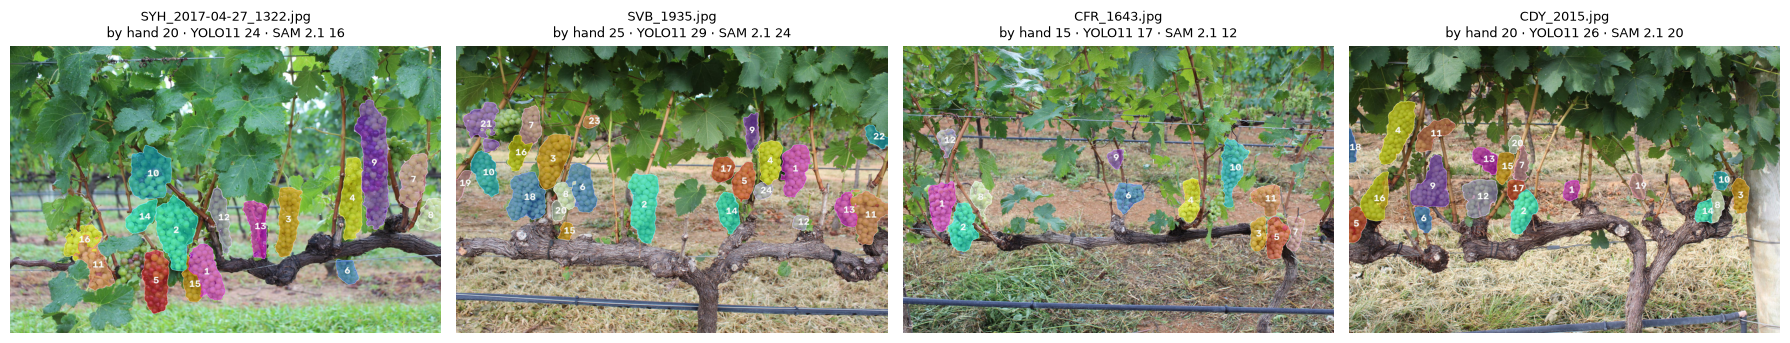

In [12]:
# Step 6: look at four photos: SAM 2.1's masks, each cluster numbered, with the three counts in the title.
import matplotlib.pyplot as plt

assert len(ok), "no photo was counted; see the status column above"
picks = ok.iloc[np.linspace(0, len(ok) - 1, min(4, len(ok))).round().astype(int)]
fig, axes = plt.subplots(1, len(picks), figsize=(18, 4.2), squeeze=False)
for ax, r in zip(axes[0], picks.itertuples()):
    ax.imshow(Image.open(OVERLAYS / r.image))
    ax.set_title(f"{r.image}\nby hand {r.truth} · YOLO11 {r.yolo} · SAM 2.1 {r.sam2}", fontsize=9)
    ax.axis("off")
plt.tight_layout(); plt.show()